<a href="https://colab.research.google.com/github/marihatabassum/Python_Data_Analysis_Projects/blob/for-freecodecamp-python-projects/sea_level_predictor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Use the data to complete the following tasks:

    1. Use Pandas to import the data from epa-sea-level.csv.
    2. Use matplotlib to create a scatter plot using the Year column as the x-axis and the CSIRO Adjusted Sea Level column as the y-axis.
    3. Use the linregress function from scipy.stats to get the slope and y-intercept of the line of best fit. Plot the line of best fit over the top of the scatter plot. Make the line go through the year 2050 to predict the sea level rise in 2050.
    4. Plot a new line of best fit just using the data from year 2000 through the most recent year in the dataset. Make the line also go through the year 2050 to predict the sea level rise in 2050 if the rate of rise continues as it has since the year 2000.
    5. The x label should be Year, the y label should be Sea Level (inches), and the title should be Rise in Sea Level.


In [ ]:
#Q1
df=pd.read_csv("/content/drive/MyDrive/FreeCodeCamp Courses/data analysis with python projects/epa-sea-level.csv")
df

,Year,CSIRO Adjusted Sea Level,Lower Error Bound,Upper Error Bound,NOAA Adjusted Sea Level
0,1880,0.000000,-0.952756,0.952756,NaN
1,1881,0.220472,-0.732283,1.173228,NaN
2,1882,-0.440945,-1.346457,0.464567,NaN
3,1883,-0.232283,-1.129921,0.665354,NaN
4,1884,0.590551,-0.283465,1.464567,NaN
...,...,...,...,...,...
139,2019,NaN,NaN,NaN,9.594329
140,2020,NaN,NaN,NaN,9.699874
141,2021,NaN,NaN,NaN,9.886688
142,2022,NaN,NaN,NaN,9.974711


In [ ]:
df.isnull().sum() # have to clean up of patch up the null data!

,0
Year,0
CSIRO Adjusted Sea Level,10
Lower Error Bound,10
Upper Error Bound,10
NOAA Adjusted Sea Level,113


In [ ]:
#df.isna()
df.isna().any()

,0
Year,False
CSIRO Adjusted Sea Level,True
Lower Error Bound,True
Upper Error Bound,True
NOAA Adjusted Sea Level,True


In [ ]:
df.describe()

,Year,CSIRO Adjusted Sea Level,Lower Error Bound,Upper Error Bound,NOAA Adjusted Sea Level
count,144.000000,134.000000,134.000000,134.000000,31.000000
mean,1951.500000,3.646404,3.201551,4.091256,8.120275
std,41.713307,2.477596,2.657303,2.302755,1.125552
min,1880.000000,-0.440945,-1.346457,0.464567,6.308803
25%,1915.750000,1.632874,1.078740,2.240157,7.197893
50%,1951.500000,3.312992,2.915354,3.710630,7.960706
75%,1987.250000,5.587598,5.329724,5.845472,9.127353
max,2023.000000,9.244094,8.917323,9.570866,10.203904


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 144 entries, 0 to 143
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Year                      144 non-null    int64  
 1   CSIRO Adjusted Sea Level  134 non-null    float64
 2   Lower Error Bound         134 non-null    float64
 3   Upper Error Bound         134 non-null    float64
 4   NOAA Adjusted Sea Level   31 non-null     float64
dtypes: float64(4), int64(1)
memory usage: 5.8 KB


In [ ]:
#filling nun values to 0 values!
cleaned_df=df.fillna(0)
cleaned_df

,Year,CSIRO Adjusted Sea Level,Lower Error Bound,Upper Error Bound,NOAA Adjusted Sea Level
0,1880,0.000000,-0.952756,0.952756,0.000000
1,1881,0.220472,-0.732283,1.173228,0.000000
2,1882,-0.440945,-1.346457,0.464567,0.000000
3,1883,-0.232283,-1.129921,0.665354,0.000000
4,1884,0.590551,-0.283465,1.464567,0.000000
...,...,...,...,...,...
139,2019,0.000000,0.000000,0.000000,9.594329
140,2020,0.000000,0.000000,0.000000,9.699874
141,2021,0.000000,0.000000,0.000000,9.886688
142,2022,0.000000,0.000000,0.000000,9.974711


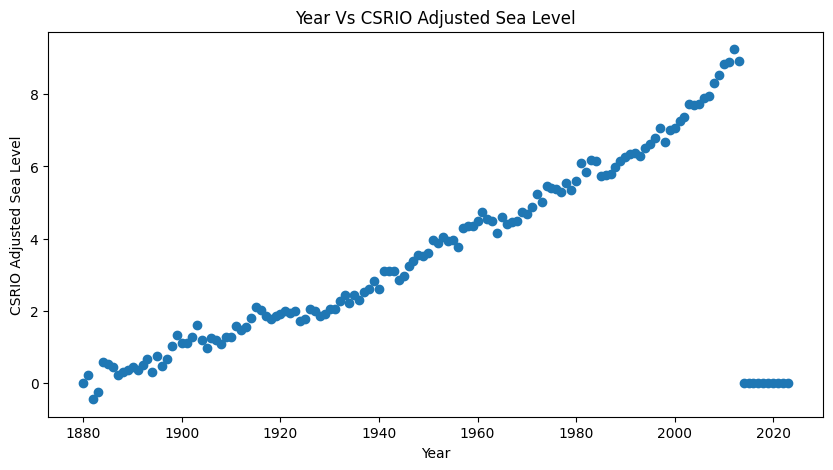

In [ ]:
#Use matplotlib to create a scatter plot using the Year column as the x-axis and the CSIRO Adjusted Sea Level column as the y-axis.

fig=plt.figure(figsize=(10, 5))
plt.scatter(x=cleaned_df.Year,y=cleaned_df["CSIRO Adjusted Sea Level"])
plt.title("Year Vs CSRIO Adjusted Sea Level")
plt.xlabel("Year")
plt.ylabel("CSRIO Adjusted Sea Level")
fig.savefig("scatter_plot_year_vs_CSRIO.png")

In [ ]:
#Use the linregress function from scipy.stats to get the slope and y-intercept of the line of best fit.
#Plot the line of best fit over the top of the scatter plot.
#Make the line go through the year 2050 to predict the sea level rise in 2050.
from scipy import stats


In [ ]:
slope, intercept, r_value, p_value, std_err= stats.linregress(cleaned_df["Year"], cleaned_df["CSIRO Adjusted Sea Level"])
# Print the results
print(f"Slope: {slope}")
print(f"Intercept: {intercept}")

Slope: 0.04084678892847037
Intercept: -76.31932727627104


Text(0, 0.5, 'CSRIO Adjusted Sea Level')

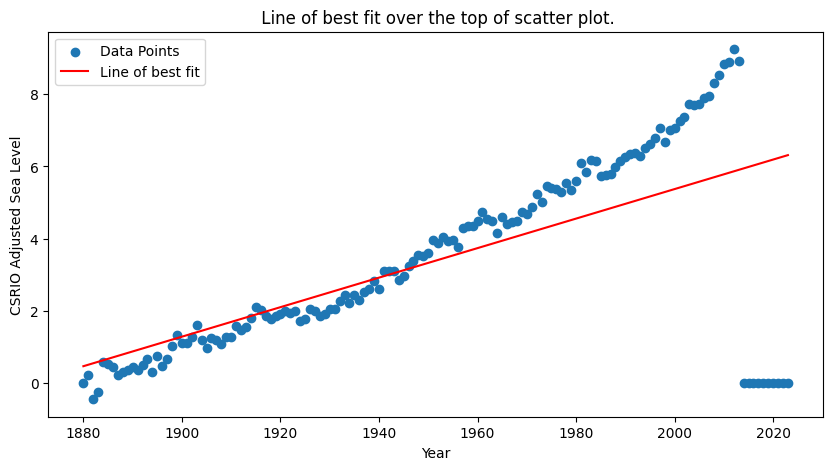

In [ ]:

fig=plt.figure(figsize=(10, 5))
plt.scatter(x=cleaned_df.Year,y=cleaned_df["CSIRO Adjusted Sea Level"], label="Data Points")
plt.plot(cleaned_df.Year, slope * cleaned_df.Year + intercept,color='red', label='Line of best fit')
plt.title(" Line of best fit over the top of scatter plot.")
plt.legend()
plt.xlabel('Year')
plt.ylabel("CSRIO Adjusted Sea Level")

In [ ]:
cleaned_df.Year.min()

1880

In [ ]:
prediction_2050=np.arange(cleaned_df["Year"].min(), 2051)
prediction_2050

array([1880, 1881, 1882, 1883, 1884, 1885, 1886, 1887, 1888, 1889, 1890,
       1891, 1892, 1893, 1894, 1895, 1896, 1897, 1898, 1899, 1900, 1901,
       1902, 1903, 1904, 1905, 1906, 1907, 1908, 1909, 1910, 1911, 1912,
       1913, 1914, 1915, 1916, 1917, 1918, 1919, 1920, 1921, 1922, 1923,
       1924, 1925, 1926, 1927, 1928, 1929, 1930, 1931, 1932, 1933, 1934,
       1935, 1936, 1937, 1938, 1939, 1940, 1941, 1942, 1943, 1944, 1945,
       1946, 1947, 1948, 1949, 1950, 1951, 1952, 1953, 1954, 1955, 1956,
       1957, 1958, 1959, 1960, 1961, 1962, 1963, 1964, 1965, 1966, 1967,
       1968, 1969, 1970, 1971, 1972, 1973, 1974, 1975, 1976, 1977, 1978,
       1979, 1980, 1981, 1982, 1983, 1984, 1985, 1986, 1987, 1988, 1989,
       1990, 1991, 1992, 1993, 1994, 1995, 1996, 1997, 1998, 1999, 2000,
       2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011,
       2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022,
       2023, 2024, 2025, 2026, 2027, 2028, 2029, 20

In [ ]:
predicted_sea_level=intercept +slope* prediction_2050
predicted_sea_level

array([0.47263591, 0.5134827 , 0.55432949, 0.59517628, 0.63602306,
       0.67686985, 0.71771664, 0.75856343, 0.79941022, 0.84025701,
       0.8811038 , 0.92195059, 0.96279738, 1.00364417, 1.04449095,
       1.08533774, 1.12618453, 1.16703132, 1.20787811, 1.2487249 ,
       1.28957169, 1.33041848, 1.37126527, 1.41211205, 1.45295884,
       1.49380563, 1.53465242, 1.57549921, 1.616346  , 1.65719279,
       1.69803958, 1.73888637, 1.77973315, 1.82057994, 1.86142673,
       1.90227352, 1.94312031, 1.9839671 , 2.02481389, 2.06566068,
       2.10650747, 2.14735426, 2.18820104, 2.22904783, 2.26989462,
       2.31074141, 2.3515882 , 2.39243499, 2.43328178, 2.47412857,
       2.51497536, 2.55582214, 2.59666893, 2.63751572, 2.67836251,
       2.7192093 , 2.76005609, 2.80090288, 2.84174967, 2.88259646,
       2.92344324, 2.96429003, 3.00513682, 3.04598361, 3.0868304 ,
       3.12767719, 3.16852398, 3.20937077, 3.25021756, 3.29106435,
       3.33191113, 3.37275792, 3.41360471, 3.4544515 , 3.49529

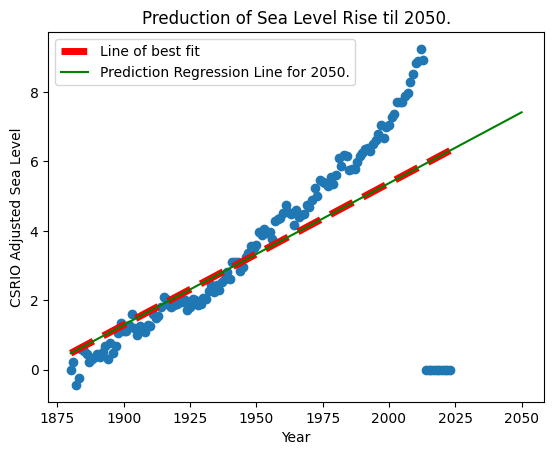

In [ ]:
plt.scatter(cleaned_df.Year, cleaned_df['CSIRO Adjusted Sea Level'])
plt.plot(cleaned_df.Year, slope * cleaned_df.Year + intercept,color='red', linewidth=5,linestyle='--', label='Line of best fit')
plt.plot(prediction_2050, predicted_sea_level, color='green',label="Prediction Regression Line for 2050." )
plt.title("Preduction of Sea Level Rise til 2050.")
plt.xlabel('Year')
plt.ylabel("CSRIO Adjusted Sea Level")
plt.legend()

In [ ]:
#Plot a new line of best fit just using the data from year 2000 through the most recent year in the dataset.
#Make the line also go through the year 2050 to predict the sea level rise in 2050 if the rate of rise continues as it has since the year 2000.
filtered_df=cleaned_df[cleaned_df['Year']>=2000]
filt_predict_20250=range(filtered_df.Year.min(), 2051)

slope2, intercept2, r_value2,p_value2, std_err2 = stats.linregress(filtered_df.Year, filtered_df["CSIRO Adjusted Sea Level"])
print(f"Slope2:{slope2}")
print(f"Intercept2: {intercept2}")

Slope2:-0.4612615537926087
Intercept2: 932.5535012757907


Text(0.5, 1.0, 'Rise in Sea Level')

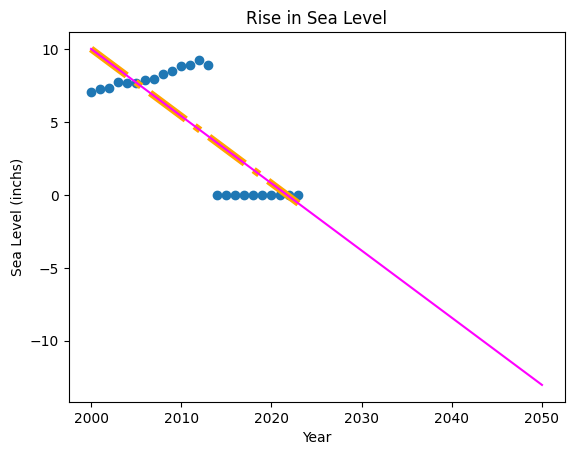

In [ ]:
plt.scatter(filtered_df.Year, filtered_df["CSIRO Adjusted Sea Level"])
plt.plot(filtered_df.Year,slope2 *filtered_df.Year +intercept2, color="orange", linewidth=5, linestyle='-.' )
plt.plot(filt_predict_20250, slope2* filt_predict_20250+intercept2, color="magenta")
plt.xlabel('Year')
plt.ylabel('Sea Level (inchs)')
plt.title("Rise in Sea Level")

In [ ]:
#The x label should be Year, the y label should be Sea Level (inches), and the title should be Rise in Sea Level.